# Project 4 - k-nearest neighbors

## Part 1

In [ ]:
#code blocks for part 1 go here
# part 1 imports
import pandas as pd
import numpy as np
import random
import seaborn as sns

import matplotlib.pyplot as plt

# read in data
df = pd.read_csv('cleveland.csv')

# making a binary for disease
df['disease'] = df.num.apply(lambda x: min(x,1))
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,disease
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2,1
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3,1
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1,1


In [27]:
from sklearn.metrics import precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
import numpy as np

# attributes to try first: trestbps, chol, oldpeak
# defining attributes and thing to predict
attributes = ['chol', 'oldpeak', 'cp', 'thalach', 'trestbps']
X = df[attributes].values
y = df['disease'].values

k_values = [3, 5, 7, 9]
n_iterations = 10

results = []

for k in k_values:
    f1_scores = []
    precision_scores = []
    recall_scores = []

    for i in range(n_iterations):
        # splitting the dataset (Monte Carlo)
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)#, random_state=42)

        # need to standardize these attributes since they are on different scales
        train_mean = X_train.mean(axis=0)
        train_std = X_train.std(axis=0)

        X_train_std = (X_train - train_mean) / train_std
        X_test_std = (X_test - train_mean if (train_std != 0).all() else X_test - train_mean)
        X_test_std = (X_test - train_mean) / train_std

        # Fit the NearestNeighbors model
        nn = NearestNeighbors(n_neighbors=k, metric='euclidean', algorithm='auto')
        nn.fit(X_train_std)

        # Get the distances and indices of the nearest neighbors for the test set
        distances, indices = nn.kneighbors(X_test_std)

        # Predict labels using majority vote of the k nearest neighbors
        y_pred = []
        for idx_row in indices:
            neighbor_labels = y_train[idx_row]
            # Majority vote (ties broken arbitrarily or towards 0)
            prediction = 1 if np.sum(neighbor_labels) > (k / 2) else 0
            y_pred.append(prediction)

        y_pred = np.array(y_pred)

        # Compute metrics for this iteration
        precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary', zero_division=0)

        f1_scores.append(f1)
        precision_scores.append(precision)
        recall_scores.append(recall)

    # Store average results for this k
    results.append({
        'k': k,
        'mean_precision': np.mean(precision_scores),
        'mean_recall': np.mean(recall_scores),
        'mean_f1': np.mean(f1_scores),
        'all_f1': f1_scores
    })

# Display results
for res in results:
    print(f"k = {res['k']} | Mean Precision: {res['mean_precision']:.3f} | Mean Recall: {res['mean_recall']:.3f} | Mean F1: {res['mean_f1']:.3f}")


k = 3 | Mean Precision: 0.661 | Mean Recall: 0.684 | Mean F1: 0.669
k = 5 | Mean Precision: 0.740 | Mean Recall: 0.679 | Mean F1: 0.704
k = 7 | Mean Precision: 0.737 | Mean Recall: 0.670 | Mean F1: 0.700
k = 9 | Mean Precision: 0.682 | Mean Recall: 0.692 | Mean F1: 0.685


## Attempts to increase the precision, recall, and mean:

Attempt 1: Using different values of k with 'trestbps', 'chol', 'oldpeak'

k = 3 | Mean Precision: 0.616 | Mean Recall: 0.528 | Mean F1: 0.564
k = 5 | Mean Precision: 0.575 | Mean Recall: 0.542 | Mean F1: 0.553
k = 7 | Mean Precision: 0.619 | Mean Recall: 0.514 | Mean F1: 0.558
k = 9 | Mean Precision: 0.637 | Mean Recall: 0.597 | Mean F1: 0.609

Attempt 2: Using different values of k with 'trestbps', 'chol', 'oldpeak', 'age'

k = 3 | Mean Precision: 0.636 | Mean Recall: 0.599 | Mean F1: 0.613
k = 5 | Mean Precision: 0.635 | Mean Recall: 0.578 | Mean F1: 0.602
k = 7 | Mean Precision: 0.645 | Mean Recall: 0.562 | Mean F1: 0.598
k = 9 | Mean Precision: 0.657 | Mean Recall: 0.575 | Mean F1: 0.610

Attempt 3: diff values of k with 'chol', 'oldpeak', 'age'

k = 3 | Mean Precision: 0.661 | Mean Recall: 0.627 | Mean F1: 0.638
k = 5 | Mean Precision: 0.666 | Mean Recall: 0.632 | Mean F1: 0.646
k = 7 | Mean Precision: 0.670 | Mean Recall: 0.630 | Mean F1: 0.645
k = 9 | Mean Precision: 0.737 | Mean Recall: 0.603 | Mean F1: 0.661

Attempt 4: 'chol', 'oldpeak', 'age', 'cp'

k = 3 | Mean Precision: 0.694 | Mean Recall: 0.645 | Mean F1: 0.665
k = 5 | Mean Precision: 0.740 | Mean Recall: 0.580 | Mean F1: 0.646
k = 7 | Mean Precision: 0.728 | Mean Recall: 0.653 | Mean F1: 0.683
k = 9 | Mean Precision: 0.767 | Mean Recall: 0.650 | Mean F1: 0.700

Attempt 5: 'chol', 'oldpeak', 'cp', 'age', 'thalach'

k = 3 | Mean Precision: 0.725 | Mean Recall: 0.680 | Mean F1: 0.696
k = 5 | Mean Precision: 0.700 | Mean Recall: 0.624 | Mean F1: 0.659
k = 7 | Mean Precision: 0.752 | Mean Recall: 0.653 | Mean F1: 0.697
k = 9 | Mean Precision: 0.779 | Mean Recall: 0.677 | Mean F1: 0.722

Attempt 5: 'chol', 'oldpeak', 'cp', 'thalach'

k = 3 | Mean Precision: 0.771 | Mean Recall: 0.665 | Mean F1: 0.711
k = 5 | Mean Precision: 0.770 | Mean Recall: 0.663 | Mean F1: 0.709
k = 7 | Mean Precision: 0.767 | Mean Recall: 0.709 | Mean F1: 0.733
k = 9 | Mean Precision: 0.726 | Mean Recall: 0.736 | Mean F1: 0.725

Attempt 6: 'chol', 'oldpeak', 'cp', 'thalach', 'trestbps'

k = 3 | Mean Precision: 0.661 | Mean Recall: 0.684 | Mean F1: 0.669
k = 5 | Mean Precision: 0.740 | Mean Recall: 0.679 | Mean F1: 0.704
k = 7 | Mean Precision: 0.737 | Mean Recall: 0.670 | Mean F1: 0.700
k = 9 | Mean Precision: 0.682 | Mean Recall: 0.692 | Mean F1: 0.685


## Part 2

In [2]:
#code blocks for part 2 go here
# part 2 set up
# in is math grades in a portugal school 1 - 20

from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import KFold
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler


df = pd.read_csv("student-mat.csv", sep=";")



In [3]:
# data cleaning

mathDF = df




if df["G3"].dtype == "object":
  df["G3"] = pd.to_numeric(df["G3"].astype(str).str.replace('"', ""))
target = (df["G3"] >= 10).astype(int)



selected_attributes = ["sex", "absences", "studytime", "failures"]
selected_attributes_data = df[selected_attributes]

# Convert categorical variables (sex, higher) into numeric dummy variables
features= pd.get_dummies(selected_attributes_data, drop_first=True)



In [4]:
def evaluate_knn_fold(X_train, y_train, X_test, y_test, k=5):
  # Scale features (critical for distance-based KNN)
  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(X_train)
  X_test_scaled = scaler.transform(X_test)

  # Use NearestNeighbors to find the k nearest neighbors
  nn = NearestNeighbors(n_neighbors=k, metric="euclidean")
  nn.fit(X_train_scaled)

  # Find neighbors for the test set
  distances, indices = nn.kneighbors(X_test_scaled)

  # Predict class via majority of neighbors
  y_pred = []
  for neighbor_indices in indices:
    neighbor_labels = y_train.iloc[neighbor_indices].values
    vote_counts = Counter(neighbor_labels)
    predicted_class = vote_counts.most_common(1)[0][0]
    y_pred.append(predicted_class)

  y_pred = np.array(y_pred)

  # Calculate classification metrics
  prec = precision_score(y_test, y_pred, zero_division=0)
  rec = recall_score(y_test, y_pred, zero_division=0)
  f1 = f1_score(y_test, y_pred, zero_division=0)

  return prec, rec, f1

In [5]:
# 4. Set up 10-Fold Cross-Validation (10 iterations)
kf = KFold(n_splits=10, shuffle=True, random_state=42)

precision_scores = []
recall_scores = []
f1_scores = []

fold = 1
for train_index, test_index in kf.split(features):
  X_train, X_test = features.iloc[train_index], features.iloc[test_index]
  y_train, y_test = target.iloc[train_index], target.iloc[test_index]

  # Call the evaluation function for this fold's dataset split
  prec, rec, f1 = evaluate_knn_fold(X_train, y_train, X_test, y_test, k=5)

  precision_scores.append(prec)
  recall_scores.append(rec)
  f1_scores.append(f1)

  print(
      f"Fold {fold:2d} | Precision: {prec:.3f} | Recall: {rec:.3f} | F1:"
      f" {f1:.3f}"
  )
  fold += 1

pass_count = target.sum()
fail_count = (target == 0).sum()

# 5. Final Summary Report
print("\n" + "=" * 50)
print("FINAL CROSS-VALIDATION SUMMARY REPORT")
print("=" * 50)
print(f"k value: 5")
print(f"Attributes used: {list(features.columns)}")
print("\nAll 10 Precision Scores:", [round(p, 3) for p in precision_scores])
print("All 10 Recall Scores:   ", [round(r, 3) for r in recall_scores])
print("All 10 F1 Scores:       ", [round(f, 3) for f in f1_scores])
print("-" * 50)
print(f"Mean Precision: {np.mean(precision_scores):.3f}")
print(f"Mean Recall:    {np.mean(recall_scores):.3f}")
print(f"Mean F1 Score:  {np.mean(f1_scores):.3f}")

print(f"Total Passing Students (1): {pass_count}")
print(f"Total Failing Students (0): {fail_count}")
print(f"Pass Rate: {(pass_count / len(target)) * 100:.1f}%\n")

Fold  1 | Precision: 0.690 | Recall: 0.800 | F1: 0.741
Fold  2 | Precision: 0.788 | Recall: 0.929 | F1: 0.852
Fold  3 | Precision: 0.581 | Recall: 0.857 | F1: 0.692
Fold  4 | Precision: 0.767 | Recall: 0.767 | F1: 0.767
Fold  5 | Precision: 0.667 | Recall: 0.957 | F1: 0.786
Fold  6 | Precision: 0.885 | Recall: 0.742 | F1: 0.807
Fold  7 | Precision: 0.806 | Recall: 0.926 | F1: 0.862
Fold  8 | Precision: 0.862 | Recall: 0.862 | F1: 0.862
Fold  9 | Precision: 0.759 | Recall: 0.815 | F1: 0.786
Fold 10 | Precision: 0.760 | Recall: 0.792 | F1: 0.776

FINAL CROSS-VALIDATION SUMMARY REPORT
k value: 5
Attributes used: ['absences', 'studytime', 'failures', 'sex_M']

All 10 Precision Scores: [0.69, 0.788, 0.581, 0.767, 0.667, 0.885, 0.806, 0.862, 0.759, 0.76]
All 10 Recall Scores:    [0.8, 0.929, 0.857, 0.767, 0.957, 0.742, 0.926, 0.862, 0.815, 0.792]
All 10 F1 Scores:        [0.741, 0.852, 0.692, 0.767, 0.786, 0.807, 0.862, 0.862, 0.786, 0.776]
--------------------------------------------------


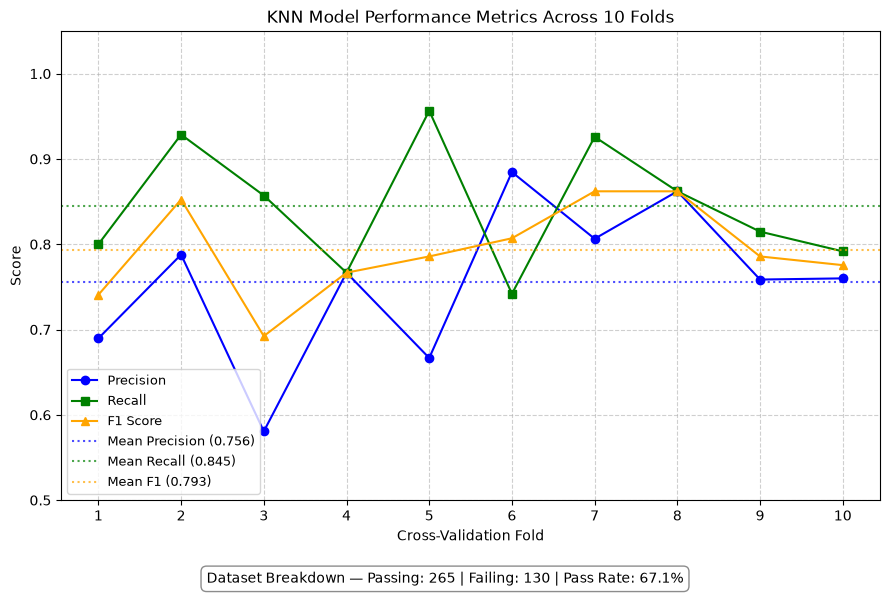

In [6]:
folds = list(range(1, 11))

# Make the figure slightly taller to leave room at the bottom for text
plt.figure(figsize=(9, 6))

# 1. Plot your 10-fold metric lines
plt.plot(folds, precision_scores, marker="o", label="Precision", color="blue")
plt.plot(folds, recall_scores, marker="s", label="Recall", color="green")
plt.plot(folds, f1_scores, marker="^", label="F1 Score", color="orange")

# 2. Calculate and plot horizontal dashed lines for the means
mean_prec = np.mean(precision_scores)
mean_rec = np.mean(recall_scores)
mean_f1 = np.mean(f1_scores)

plt.axhline(
    mean_prec,
    color="blue",
    linestyle=":",
    alpha=0.7,
    label=f"Mean Precision ({mean_prec:.3f})",
)
plt.axhline(
    mean_rec,
    color="green",
    linestyle=":",
    alpha=0.7,
    label=f"Mean Recall ({mean_rec:.3f})",
)
plt.axhline(
    mean_f1,
    color="orange",
    linestyle=":",
    alpha=0.7,
    label=f"Mean F1 ({mean_f1:.3f})",
)

plt.title("KNN Model Performance Metrics Across 10 Folds")
plt.xlabel("Cross-Validation Fold")
plt.ylabel("Score")
plt.ylim(0.5, 1.05)
plt.xticks(folds)
plt.legend(loc="lower left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.6)

# 3. Add total pass/fail info at the bottom of the chart
pass_rate_pct = (pass_count / (pass_count + fail_count)) * 100
info_text = (
    f"Dataset Breakdown — Passing: {pass_count} | Failing: {fail_count} | Pass"
    f" Rate: {pass_rate_pct:.1f}%"
)

plt.figtext(
    0.5,
    0.02,
    info_text,
    ha="center",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9,
    ),
)

# Adjust layout so the bottom text doesn't get cut off
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()



# folds = list(range(1, 11))

# plt.figure(figsize=(9, 5))
# plt.plot(folds, precision_scores, marker="o", label="Precision", color="blue")
# plt.plot(folds, recall_scores, marker="s", label="Recall", color="green")
# plt.plot(folds, f1_scores, marker="^", label="F1 Score", color="orange")

# plt.title("Model Performance Metrics Across 10 Folds")
# plt.xlabel("Cross-Validation Fold")
# plt.ylabel("Score")
# plt.ylim(0.5, 1.0)
# plt.xticks(folds)
# plt.legend()
# plt.grid(True, linestyle="--", alpha=0.6)
# plt.show()

